In [1]:
PACKAGES="torch transformers accelerate pandas matplotlib tqdm"
!uv pip install {PACKAGES} || pip install {PACKAGES}
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm  # Text bars work without Jupyter widget support.
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset, Subset

seed = 42
torch.manual_seed(seed)
max_tokens = 300  # Total tokens per chunk, including special tokens.
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Checked 6 packages in 7ms
Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


In [2]:
# Fine-tune on the complete original dataset with its original model labels.
dataset_path = Path("data/train.csv")
training_examples_df = pd.read_csv(dataset_path)
required_columns = ["id", "prompt_id", "text", "model"]
missing_columns = set(required_columns) - set(training_examples_df.columns)
if missing_columns:
    raise ValueError(f"Missing dataset columns: {sorted(missing_columns)}")
if training_examples_df[required_columns].isna().any().any():
    raise ValueError("Training examples must have non-null IDs, prompts, texts, and labels")
if training_examples_df.empty or training_examples_df["text"].str.strip().eq("").any():
    raise ValueError("Training dataset must contain nonempty response texts")
training_examples_df = training_examples_df[required_columns].reset_index(drop=True)
print(
    f"Classifier fine-tuning: {len(training_examples_df):,} responses, "
    f"{training_examples_df['model'].nunique()} classes, "
    f"{training_examples_df['prompt_id'].nunique()} prompts from {dataset_path}"
)
training_examples_df.head()


Classifier fine-tuning: 2,699 responses, 18 classes, 150 prompts from data/train.csv


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [3]:
model_name = "openai-community/roberta-large-openai-detector"
tokenizer = AutoTokenizer.from_pretrained(model_name)
# Load the pretrained detector; replace its binary head below for our model classes.
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)

train_df = training_examples_df.copy()
models = {name: i for i, name in enumerate(sorted(train_df["model"].unique()))}

train_df["model_class"] = train_df["model"].map(models)

# Split long texts into non-overlapping chunks; retain every token and its label.
encoded_text = tokenizer(
    train_df["text"].fillna("").tolist(),
    padding="max_length",
    truncation=True,
    max_length=max_tokens,
    return_overflowing_tokens=True,
    stride=0,
    return_tensors="pt",
)
# Each chunk inherits the original example and prompt ID, preventing split leakage.
source_rows = encoded_text.pop("overflow_to_sample_mapping").tolist()
train_df = train_df.iloc[source_rows].reset_index(drop=True)
train_df["text_tokens"] = encoded_text["input_ids"].tolist()
train_df["attention_mask"] = encoded_text["attention_mask"].tolist()

# model_class is a categorical index, not a numeric regression target.
# model_ohe is its one-hot vector; vector positions match the class indices.
y_train = torch.tensor(train_df["model_class"].to_numpy(), dtype=torch.long)
y_train_ohe = F.one_hot(y_train, num_classes=len(models)).float()
train_df["model_ohe"] = y_train_ohe.tolist()

train_df

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: openai-community/roberta-large-openai-detector
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,id,prompt_id,text,model,model_class,text_tokens,attention_mask,model_ohe
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,17,"[0, 1779, 10, 2777, 8524, 6, 10, 1989, 36095, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,4,"[0, 30383, 2866, 1822, 948, 142, 51, 10107, 22...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ..."
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,6,"[0, 1121, 5, 507, 38262, 9, 86, 6, 5, 94, 2841...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ..."
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra,14,"[0, 30383, 2866, 1822, 948, 142, 51, 1004, 10,...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash,10,"[0, 35166, 1025, 349, 5567, 6, 130, 5262, 3748...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
...,...,...,...,...,...,...,...,...
2778,ff4344ceda23,p075,"Across centuries of silence and shadow, an inv...",gemini-3.8-flash,8,"[0, 42945, 11505, 9, 7308, 8, 9099, 6, 41, 207...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ..."
2779,ff507658ba82,p092,Though both instruments breathe the exact same...,gemini-3.7-flash,7,"[0, 26223, 258, 9571, 14575, 5, 6089, 276, 645...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, ..."
2780,ff50c252810c,p113,A single photon leaves the star as neither wav...,claude-opus-4-8,2,"[0, 250, 881, 44635, 3607, 5, 999, 25, 5063, 4...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2781,ffcf6321f7e9,p073,Data science communities matter because they t...,glm-5.3,9,"[0, 30383, 2866, 1822, 948, 142, 51, 7891, 806...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


In [4]:
print(train_df["text_tokens"].iloc[0])

X_train = encoded_text["input_ids"]
attention_mask_train = encoded_text["attention_mask"]
# y_train holds class indices; y_train_ohe holds one-hot labels.
train_df[["text_tokens", "model_class", "model_ohe"]]

[0, 1779, 10, 2777, 8524, 6, 10, 1989, 36095, 14548, 29, 35, 45, 129, 2523, 13, 2690, 6, 53, 1086, 25187, 119, 2726, 9, 1503, 14, 5850, 6864, 141, 7, 1166, 5, 363, 4, 993, 39279, 5456, 5, 6360, 30, 41490, 4128, 6, 17014, 5, 36713, 4846, 7, 22519, 6, 12323, 6, 50, 5, 8702, 14561, 9, 7723, 131, 643, 46855, 21641, 17369, 25, 47041, 6, 98, 86, 16, 45, 10, 516, 53, 10, 16331, 8016, 4, 83, 2136, 64, 2324, 5, 6089, 3195, 9, 14131, 15, 1958, 6, 5, 35630, 9, 2686, 7, 4775, 6, 50, 5, 25634, 31605, 88, 17839, 32895, 8, 11651, 999, 12201, 4, 590, 23989, 6, 167, 3115, 6277, 88, 7308, 4, 440, 36451, 64, 36839, 5, 6360, 167, 6864, 36308, 6, 3486, 5, 5128, 10250, 24, 5850, 4, 166, 2217, 43721, 14, 156, 5, 9468, 11179, 6, 13557, 6, 8, 4299, 6, 12793, 119, 20643, 11, 61, 15073, 16, 10, 30443, 6, 3137, 2580, 32, 8383, 2584, 30, 6774, 6, 8, 10759, 1641, 1635, 32, 45, 4460, 3493, 53, 10175, 9582, 4, 20, 872, 16, 45, 8315, 36912, 3569, 131, 24, 16, 5, 3335, 24669, 9, 678, 1050, 5274, 7, 5170, 4, 653, 1189, 

,text_tokens,model_class,model_ohe
0,"[0, 1779, 10, 2777, 8524, 6, 10, 1989, 36095, ...",17,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,"[0, 30383, 2866, 1822, 948, 142, 51, 10107, 22...",4,"[0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ..."
2,"[0, 1121, 5, 507, 38262, 9, 86, 6, 5, 94, 2841...",6,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ..."
3,"[0, 30383, 2866, 1822, 948, 142, 51, 1004, 10,...",14,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,"[0, 35166, 1025, 349, 5567, 6, 130, 5262, 3748...",10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
...,...,...,...
2778,"[0, 42945, 11505, 9, 7308, 8, 9099, 6, 41, 207...",8,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ..."
2779,"[0, 26223, 258, 9571, 14575, 5, 6089, 276, 645...",7,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, ..."
2780,"[0, 250, 881, 44635, 3607, 5, 999, 25, 5063, 4...",2,"[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2781,"[0, 30383, 2866, 1822, 948, 142, 51, 7891, 806...",9,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


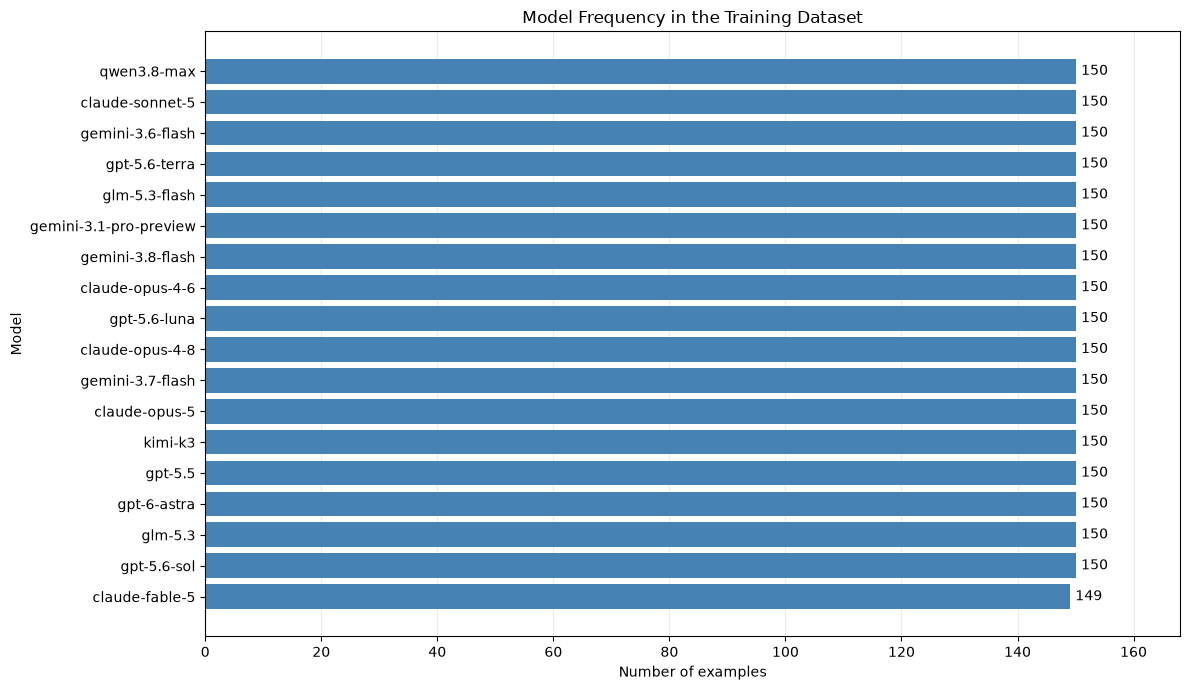

In [5]:
import matplotlib.pyplot as plt

# Count original responses before token chunking and splitting.
model_counts = training_examples_df["model"].value_counts()

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(model_counts.index, model_counts.values, color="steelblue")
ax.invert_yaxis()
ax.bar_label(bars, padding=4, fmt="%d")
ax.set_title("Model Frequency in the Training Dataset")
ax.set_xlabel("Number of examples")
ax.set_ylabel("Model")
ax.set_xlim(0, model_counts.max() * 1.12)
ax.xaxis.grid(True, alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


In [6]:
class TextClassifierHead(torch.nn.Module):
    def __init__(self, in_features=1024, out_features=2, dropout=0.1):
        super().__init__()
        if out_features < 1:
            raise ValueError("out_features must be at least 1")
        self.in_features = in_features
        self.out_features = out_features
        self.dropout = torch.nn.Dropout(dropout)
        self.dense = torch.nn.Linear(in_features, in_features)
        self.out_proj = torch.nn.Linear(in_features, out_features)
        self.softmax = torch.nn.Softmax(dim=-1)

    def forward(self, features, return_probabilities=False, **kwargs):
        # RoBERTa passes hidden states with shape (batch, sequence, hidden).
        x = self.dropout(features[:, 0, :])
        x = torch.tanh(self.dense(x))
        logits = self.out_proj(self.dropout(x))
        # Cross-entropy needs logits; request probabilities for inference.
        return self.softmax(logits) if return_probabilities else logits

    def predict_proba(self, features):
        return self(features, return_probabilities=True)


In [7]:
# Replace the binary detector head with a fresh model-label classifier.
# Its input width is taken from the loaded backbone configuration.
old_head_parameter = next(model.classifier.parameters())
# More head dropout helps regularize the smaller training dataset.
head_dropout = 0.2
model.config.classifier_dropout = head_dropout

new_head = TextClassifierHead(
    in_features=model.config.hidden_size,
    out_features=len(models),
    dropout=head_dropout,
)
new_head.apply(model._init_weights)
model.classifier = new_head.to(
    device=old_head_parameter.device,
    dtype=old_head_parameter.dtype,
)

model.num_labels = len(models)
model.config.num_labels = len(models)
model.config.label2id = dict(models)
model.config.id2label = {index: name for name, index in models.items()}
model.config.problem_type = "single_label_classification"

# Fine-tune only the new classifier; preserve all pretrained backbone weights.
model.requires_grad_(False)
model.classifier.requires_grad_(True)
model.base_model.eval()
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable classifier parameters: {trainable_parameters:,}")

# Pass integer y_train labels to model(..., labels=...) for cross-entropy loss.
model


Trainable classifier parameters: 1,068,050


RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, b

In [8]:


seed = 42
batch_size = 16*4
num_epochs = 1000  # Maximum; early stopping selects the actual duration.
learning_rate = 3e-4
weight_decay = 0.01
validation_fraction = 0.2
early_stopping_patience = 3
min_delta = 1e-4
checkpoint_path = Path("checkpoints/roberta_large_detector_train_csv/best_classifier.pt")

torch.manual_seed(seed)

# Hold out entire prompts to prevent prompt overlap between train and validation.
prompt_ids = train_df["prompt_id"].drop_duplicates().sample(frac=1, random_state=seed)
if len(prompt_ids) < 2:
    raise ValueError("At least two distinct prompts are needed for validation")
num_val_prompts = max(1, min(len(prompt_ids) - 1, round(len(prompt_ids) * validation_fraction)))
is_validation = train_df["prompt_id"].isin(prompt_ids.iloc[:num_val_prompts])
train_indices = torch.tensor((~is_validation).to_numpy()).nonzero(as_tuple=True)[0].tolist()
val_indices = torch.tensor(is_validation.to_numpy()).nonzero(as_tuple=True)[0].tolist()

dataset = TensorDataset(X_train, attention_mask_train, y_train)
train_loader = DataLoader(
    Subset(dataset, train_indices), batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(seed),
)
val_loader = DataLoader(Subset(dataset, val_indices), batch_size=batch_size)

# Use the pretrained model device; optimize only the classifier head.
device = model.get_input_embeddings().weight.device
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=learning_rate, weight_decay=weight_decay,
)
print(f"Device: {device} | Training: {len(train_indices)} | Validation: {len(val_indices)}")

# Count only training chunks; validation does not influence the weights.
class_counts = torch.bincount(y_train[train_indices], minlength=len(models)).float()
class_weights = torch.zeros_like(class_counts)
present_classes = class_counts > 0
class_weights[present_classes] = class_counts[present_classes].rsqrt()
class_weights[present_classes] /= class_weights[present_classes].mean()
class_weights = class_weights.to(device)
class_balance_df = pd.DataFrame({
    "model": [model.config.id2label[i] for i in range(len(models))],
    "training_chunks": class_counts.long().tolist(),
    "loss_weight": class_weights.cpu().tolist(),
})
if not present_classes.all():
    print("Classes absent from training:", class_balance_df.loc[~present_classes.numpy(), "model"].tolist())
class_balance_df


Device: cuda:0 | Training: 2216 | Validation: 567


,model,training_chunks,loss_weight
0,claude-fable-5,123,1.000367
1,claude-opus-4-6,124,0.996325
2,claude-opus-4-8,124,0.996325
3,claude-opus-5,126,0.988386
4,claude-sonnet-5,127,0.984487
5,gemini-3.1-pro-preview,124,0.996325
6,gemini-3.6-flash,122,1.004458
7,gemini-3.7-flash,125,0.992332
8,gemini-3.8-flash,120,1.012794
9,glm-5.3,123,1.000367


In [9]:


def run_epoch(model, loader, device, optimizer=None, description="Training", class_weights=None, batch_losses=None):
    training = optimizer is not None
    model.train(training)
    # Disable dropout in the frozen backbone while training classifier dropout.
    model.base_model.eval()
    total_loss, total_correct, total_examples = 0.0, 0, 0
    total_loss_weight = 0.0
    confusion = torch.zeros(model.num_labels, model.num_labels, dtype=torch.long)

    with torch.set_grad_enabled(training), tqdm(
        loader, desc=description, unit="batch", leave=True,
        mininterval=1.0, dynamic_ncols=True,
    ) as progress:
        for input_ids, attention_mask, labels in progress:
            # Trim trailing padding to the longest text in this batch.
            sequence_length = int(attention_mask.sum(dim=1).max().item())
            input_ids = input_ids[:, :sequence_length].to(device)
            attention_mask = attention_mask[:, :sequence_length].to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(
                input_ids=input_ids, attention_mask=attention_mask,
            )
            # Balance training only; retain ordinary cross-entropy for validation.
            weights = class_weights if training else None
            loss = F.cross_entropy(outputs.logits, labels, weight=weights)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss encountered during training/validation")

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.classifier.parameters(), max_norm=1.0)
                optimizer.step()

            batch_loss = loss.item()
            if training and batch_losses is not None:
                batch_losses.append(batch_loss)

            count = labels.size(0)
            loss_weight = weights[labels].sum().item() if weights is not None else count
            total_loss += batch_loss * loss_weight
            total_loss_weight += loss_weight
            predictions = outputs.logits.argmax(dim=-1)
            confusion += torch.bincount(
                (labels * model.num_labels + predictions).detach().cpu(),
                minlength=model.num_labels ** 2,
            ).reshape(model.num_labels, model.num_labels)
            total_correct += (outputs.logits.argmax(dim=-1) == labels).sum().item()
            total_examples += count
            progress.set_postfix(
                loss=f"{total_loss / total_loss_weight:.4f}",
                accuracy=f"{total_correct / total_examples:.2%}",
                refresh=False,
            )

    support = confusion.sum(dim=1)
    predicted = confusion.sum(dim=0)
    true_positive = confusion.diag().float()
    recall = true_positive / support.clamp_min(1)
    f1 = 2 * true_positive / (support + predicted).clamp_min(1)
    active = (support + predicted) > 0
    metrics = {
        "macro_f1": f1[active].mean().item(),
        "per_class_recall": {
            model.config.id2label[i]: recall[i].item() if support[i] else None
            for i in range(model.num_labels)
        },
    }
    return total_loss / total_loss_weight, total_correct / total_examples, metrics


history = []
best_val_loss = float("inf")
epochs_without_improvement = 0
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(1, num_epochs + 1):
    print(f"\nEpoch {epoch}/{num_epochs}", flush=True)
    # Append before training so completed batches survive a cell interrupt.
    epoch_history = {
        "epoch": epoch, "train_batch_losses": [],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(epoch_history)
    train_loss, train_accuracy, train_metrics = run_epoch(
        model, train_loader, device, optimizer,
        description=f"Epoch {epoch}/{num_epochs} train", class_weights=class_weights,
        batch_losses=epoch_history["train_batch_losses"],
    )
    val_loss, val_accuracy, val_metrics = run_epoch(
        model, val_loader, device,
        description=f"Epoch {epoch}/{num_epochs} validation",
    )
    epoch_history.update({
        "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy,
        "val_loss": val_loss, "val_accuracy": val_accuracy,
        "train_macro_f1": train_metrics["macro_f1"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_per_class_recall": val_metrics["per_class_recall"],
    })
    print(
        f"Epoch {epoch}/{num_epochs} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.2%}, "
        f"macro F1 {val_metrics['macro_f1']:.4f}",
        flush=True,
    )

    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        # Include configuration and label mapping for the custom classifier head.
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "dataset_path": str(dataset_path),
            "hyperparameters": {
                "batch_size": batch_size, "max_tokens": max_tokens,
                "num_epochs": num_epochs, "learning_rate": learning_rate,
                "weight_decay": weight_decay, "head_dropout": head_dropout,
                "validation_fraction": validation_fraction, "seed": seed,
                "early_stopping_patience": early_stopping_patience,
                "min_delta": min_delta,
            },
            "config": model.config.to_dict(),
            "pretrained_model_name": model_name,
            "training_mode": "classifier_head_only",
            "label2id": dict(models),
            "selected_models": list(models),
            "class_weights": class_weights.detach().cpu(),
            "training_class_counts": class_counts,
            "val_loss": val_loss,
            "history": history,
        }, checkpoint_path)
        tokenizer.save_pretrained(checkpoint_path.parent)
        # Save the pretrained backbone alongside this dataset's trained head.
        model.base_model.save_pretrained(checkpoint_path.parent / "backbone")
        tokenizer.save_pretrained(checkpoint_path.parent / "backbone")
        print(f"Saved best checkpoint to {checkpoint_path}")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stopping_patience:
        print(f"Early stopping after {early_stopping_patience} epochs without validation improvement.")
        break

# None marks classes with no validation examples.
val_recall_df = pd.DataFrame.from_dict(
    val_metrics["per_class_recall"], orient="index", columns=["recall"],
).rename_axis("model")
display(val_recall_df)
history_df = pd.DataFrame(history)
history_df



Epoch 1/1000


Epoch 1/1000 validation: 100%|██████████| 9/9 [00:05<00:00,  1.76batch/s, accuracy=6.17%, loss=2.9247]

Epoch 1/1000 | train loss 2.9884, accuracy 6.54% | val loss 2.9247, accuracy 6.17%, macro F1 0.0159


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best checkpoint to checkpoints/roberta_large_detector_train_csv/best_classifier.pt

Epoch 2/1000


...

Epoch 13/1000 | train loss 2.7149, accuracy 11.06% | val loss 2.7764, accuracy 10.05%, macro F1 0.0672

Epoch 14/1000



Epoch 14/1000 validation: 100%|██████████| 9/9 [00:04<00:00,  1.85batch/s, accuracy=9.88%, loss=2.7464] 

Epoch 14/1000 | train loss 2.6887, accuracy 11.55% | val loss 2.7464, accuracy 9.88%, macro F1 0.0478
Early stopping after 3 epochs without validation improvement.


,recall
model,
claude-fable-5,0.000000
claude-opus-4-6,0.027778
claude-opus-4-8,0.000000
claude-opus-5,0.031250
claude-sonnet-5,0.000000
gemini-3.1-pro-preview,0.000000
gemini-3.6-flash,0.032258
gemini-3.7-flash,0.000000
gemini-3.8-flash,0.411765


,epoch,train_batch_losses,learning_rate,train_loss,train_accuracy,val_loss,val_accuracy,train_macro_f1,val_macro_f1,val_per_class_recall
0,1,"[2.9403390884399414, 3.0072429180145264, 3.080...",0.0003,2.988382,0.065433,2.924669,0.061728,0.057784,0.015881,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."
1,2,"[2.8857789039611816, 2.7866694927215576, 3.013...",0.0003,2.915942,0.072202,2.890081,0.086420,0.065700,0.030085,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."
2,3,"[2.851165533065796, 2.868077039718628, 2.82994...",0.0003,2.890306,0.084386,2.905522,0.049383,0.079836,0.017307,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."
3,4,"[2.8682029247283936, 2.7678728103637695, 2.934...",0.0003,2.886267,0.081227,2.948417,0.056437,0.076835,0.020955,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."
4,5,"[2.953922748565674, 2.821516990661621, 2.77625...",0.0003,2.853668,0.092509,2.877221,0.081129,0.087730,0.037201,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."
5,6,"[2.8162312507629395, 2.9686102867126465, 2.937...",0.0003,2.847600,0.088448,2.850406,0.077601,0.086436,0.036122,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."
6,7,"[2.7078700065612793, 2.811192035675049, 2.8342...",0.0003,2.818918,0.087094,2.843739,0.098765,0.083090,0.048218,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.2..."
7,8,"[2.680690050125122, 2.701138496398926, 2.88032...",0.0003,2.793051,0.106047,2.813498,0.086420,0.100485,0.044677,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.1..."
8,9,"[2.7503676414489746, 2.7935426235198975, 2.697...",0.0003,2.768922,0.110560,2.787180,0.095238,0.103485,0.055187,"{'claude-fable-5': 0.4848484992980957, 'claude..."
9,10,"[2.7994191646575928, 2.6792914867401123, 2.764...",0.0003,2.761419,0.103791,2.760534,0.104056,0.099952,0.047691,"{'claude-fable-5': 0.0, 'claude-opus-4-6': 0.0..."


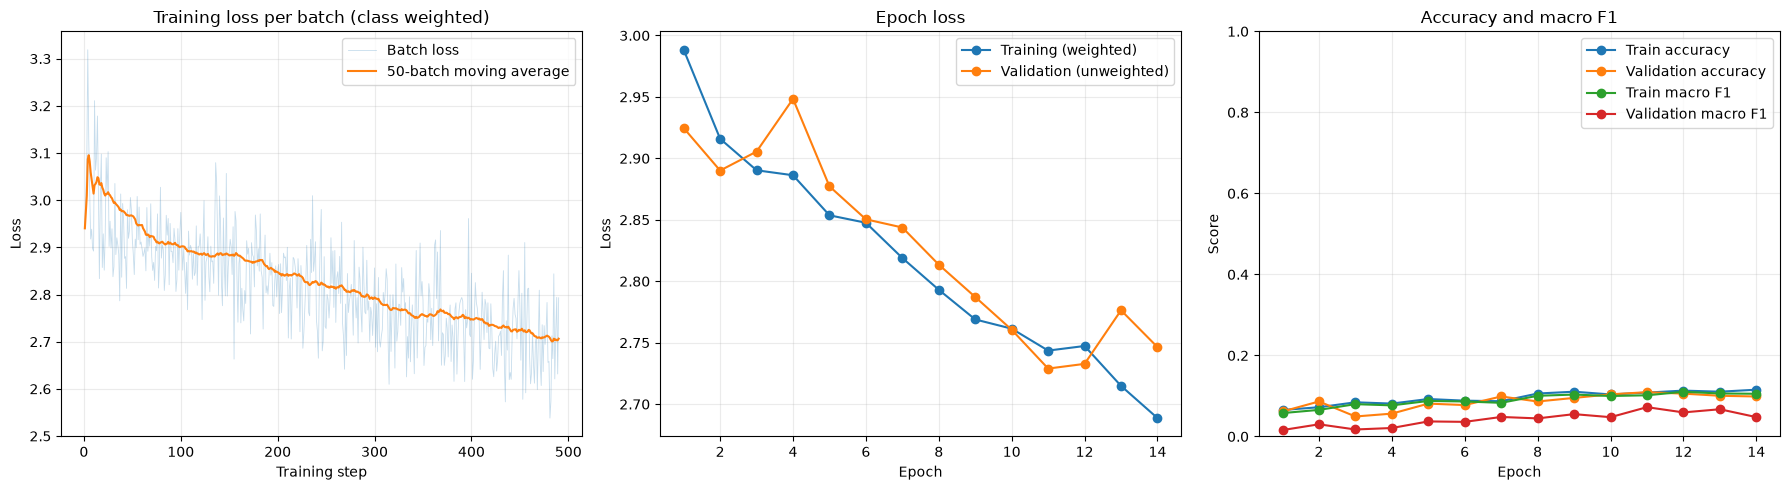

In [10]:
import matplotlib.pyplot as plt

# Rebuild from history so this also works after interrupting a training epoch.
history_df = pd.DataFrame(history)
batch_history_df = pd.DataFrame([
    {"epoch": entry["epoch"], "batch": batch, "train_loss": loss}
    for entry in history
    for batch, loss in enumerate(entry.get("train_batch_losses", []), start=1)
])
if batch_history_df.empty:
    print("No batch losses recorded yet. Run the updated training cell first.")
else:
    batch_history_df["step"] = range(1, len(batch_history_df) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].plot(batch_history_df["step"], batch_history_df["train_loss"],
                 alpha=0.25, linewidth=0.6, label="Batch loss")
    axes[0].plot(batch_history_df["step"],
                 batch_history_df["train_loss"].rolling(50, min_periods=1).mean(),
                 label="50-batch moving average")
    axes[0].set(title="Training loss per batch (class weighted)", xlabel="Training step", ylabel="Loss")
    for column, label in (("train_loss", "Training (weighted)"), ("val_loss", "Validation (unweighted)")):
        if column in history_df:
            axes[1].plot(history_df["epoch"], history_df[column], marker="o", label=label)
    axes[1].set(title="Epoch loss", xlabel="Epoch", ylabel="Loss")
    for column, label in (("train_accuracy", "Train accuracy"), ("val_accuracy", "Validation accuracy"),
                          ("train_macro_f1", "Train macro F1"), ("val_macro_f1", "Validation macro F1")):
        if column in history_df:
            axes[2].plot(history_df["epoch"], history_df[column], marker="o", label=label)
    axes[2].set(title="Accuracy and macro F1", xlabel="Epoch", ylabel="Score", ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=0.25)
        if ax.lines:
            ax.legend()
    fig.tight_layout()
    plt.show()


In [11]:
@torch.no_grad()
def predict_model_probabilities(texts):
    if isinstance(texts, str):
        texts = [texts]
    inputs = tokenizer(
        texts, padding=True, truncation=True,
        max_length=max_tokens, return_tensors="pt",
    ).to(model.get_input_embeddings().weight.device)
    was_training = model.training
    model.eval()
    try:
        probabilities = model.classifier.softmax(model(**inputs).logits)
    finally:
        model.train(was_training)
        model.base_model.eval()
    # Each column is a model category, ordered by its integer class index.
    class_names = [model.config.id2label[i] for i in range(model.num_labels)]
    return pd.DataFrame(probabilities.cpu().float().numpy(), columns=class_names)

# Example: one probability per model; each row sums to 1.
# predict_model_probabilities(train_df["text"].iloc[:3].tolist())
